# E62: Taught to copy at a new marker, does the model use its old copying head, and does r follow?

**The answer.** r was not scored. The filed rule needed the copy map to lose at least half of its gain on every seed with the model's copying head off. One seed of three lost 0.47. Unscored, the run still shows that the head matters to the copy map and not at all to the lookup. The two maps also read very different r at close priors on one measure. Yet the copy map's target sits in its own context and its update is smaller, so that gap cannot yet be credited to mechanism. A later read, the section Amendment 2 at the end, found the masked gain does not fall with the head while the masks stay frozen. That read could not test the question. Amendment 3 then recomputed the masks with the head off, and the masked gain fell. So the masks follow the head on this map, which still does not show that r reads that mechanism.


## What we were trying to test

Elicitation, in the user's sense, means the fine-tuned behaviour runs through a mechanism the original model already has. Every earlier map on this 67M model had "old mechanism" and "answer already given" pointing the same way. This test tries to pull them apart.

The original model copies in context: after "A B ... A" it tends to say B. We put a rare marker after the second A and train two fine-tunes on the same 41-token windows, three seeds each.

- **Copy map.** "A B ... A marker" should give B. The Bs on the read windows are never trained, so the map must really copy.
- **Lookup.** "A marker" should give A's own fixed word, one word for each of 32 keys. The word never occurs in that key's windows, so the copying head cannot produce it. It is the arm that should not need the old mechanism.

The words were drawn so that the original model rates them about as likely as B at the marker. That removes the prior as an explanation: E58 found r tracks the prior closely over eight maps.

The label uses no decomposition. We found the heads the original model copies with by the Olsson et al. prefix score. We then replaced each such head's output by its mean over ordinary text, and asked what share of the log-odds gain goes. Olsson et al. zero the head instead; the departures are listed near the end. One head cleared the bar: block 2, head 4. Five single other heads, drawn at random, are the floor. Two more controls guard the copy map. With the first A overwritten by another key, a true prefix match should fall. With B overwritten, a real copy cannot produce it.

Only then comes r, the candidate instrument. It is the share of the target's gain reached when the subcomponents stay original and only the mask from Γ, the causal-importance function, changes.

## What we expected, and why

If r reads mechanism, the copy map should lose at least half its gain and read high. The lookup should lose at most a fifth and read low, with 0.5 as the cut. If r reads the prior, both should read alike. From E58's nearby maps the prior alone predicted about 0.75 for both. We also leaned that the copy map would need many steps, since its query must move from the marker to the token before it.

## How much of each fine-tune goes when the copying head is off?

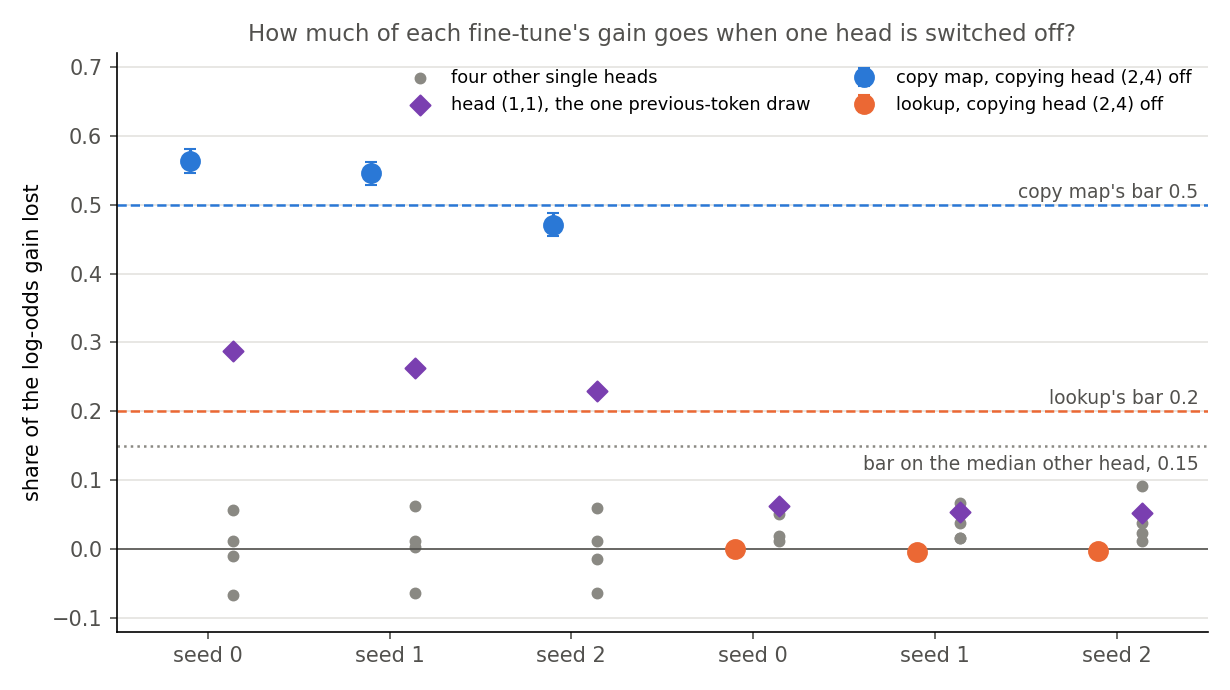

In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/induction_cue/figures")
display(Image(filename=str(FIG / "share.png")))

**Reading it.** About half for the copy map, nothing for the lookup. Against the bar of 0.5, seeds 0 and 1 clear it and seed 2 reads 0.47, so the filed label fails. The orange points sit on zero, below every other head. This is what the verdict's name hides: the copy map plainly uses the head, by an amount that straddles the bar. Row noise is about 0.016 and the seed range 0.09, so the fine-tunes differ. Seed 2's miss itself is 1.8 row sds, which is not shown to be beyond sampling. Olsson et al. zero a head; we use its mean, as approved.

In log-odds, a gain of about 12.6 falls to about 6, relative to an original with the head off that was never read. The run saved the gain under ablation, not the original's level under ablation. We take that level to lie between its unablated value and its value with B absent. At the mean log-odds, the probability of B then falls from 0.99 to a value in a range from 0.1% to 19%. That is not a bound on the mean probability, so the behaviour may largely go. If the head's removal lowers the original, the share has the same low start as r. At the bracket's far end the state's own fall is 0.80 to 0.89 of the gain. So "about half" could be a large underestimate, and the odds left can be largely a lowered floor. The original's top-1 copying falls to 0.01 under the same head. That is a different measure on a different format, so the 0.5 bar has no reference on its own scale.

The purple diamonds are head `(1,1)`, the one draw far above the rest. It costs the copy map about a quarter and the lookup about a twentieth. It is the strongest previous-token head, and switching it off alone also takes the original's top-1 to 0.013. That is what two steps of one chain do, so the evidence points to it acting in series with the copying head. Its cost may sit inside the share already. So it gives no evidence that reuse exceeds the share until the two are read together, which Amendment 2 at the end of this notebook does.


## Did the fine-tune learn prefix-matched copying, or something looser?

| seed | gain with first A overwritten, as a share of the gain: step 30 / 100 / 300 | probability of B at the mean log-odds, step 30 / 300 | gap to the intact pair in log-odds, step 30 / 300 |
|---|---|---|---|
| 0 | 0.40 / 0.55 / 0.58 | 1.0% / 13% | 9.2 / 7.2 |
| 1 | 0.34 / 0.52 / 0.59 | 0.5% / 14% | 10.0 / 7.1 |
| 2 | 0.54 / 0.50 / 0.63 | 5.7% / 25% | 7.3 / 6.5 |

**Reading it.** Both, and the looser part grows. The filed bar of 0.5 fires on seed 2 at the read step, and would fire on all three by step 300. Yet the pair is far from ignored. Overwriting the first A still drops B by at least 6 log-odds, against 1.6 in the original model. The share misleads here because its baseline falls too. With B gone from the window, B's own log-odds fall by about 8, so the marker did not learn a general lean toward these tokens.

Does this weaken "old mechanism"? Only partly. The original model also has a loose part: B anywhere in the window raises it by a factor of 14. The intact pair adds a further factor of 5. So looser copying is old too. The claim narrows to "copying from context, partly prefix-matched". Whether the loose part runs through the head was not read.

One hypothesis from the independent check, not a finding: the head may carry the pair-matched part, and the remainder may be the looser copying. What survives with the head off tracks the gain with the pair broken: 5.53 beside 5.01, 5.75 beside 4.25, 6.64 beside 6.84. If so, the share may fall to about 0.4 by step 300, and "reuses an old head" would be a statement about step 30. Neither read has been taken.

## Where does r come from? Provisional, not scored

The cells are mean log-odds of the target at the marker, each with one state of the subcomponents and one mask:

- $T_0, T_1$: the target model, original and fine-tuned.
- $U_0, U_1$: all subcomponents on, original and split.
- $L_{00}$: original subcomponents, the original mask. $L_{01}$: original subcomponents, the fine-tuned state's mask.
- $L_{10}, L_{11}$: split subcomponents, under the original and the new mask.

Then $r = (L_{01} - L_{00})/(T_1 - T_0)$.

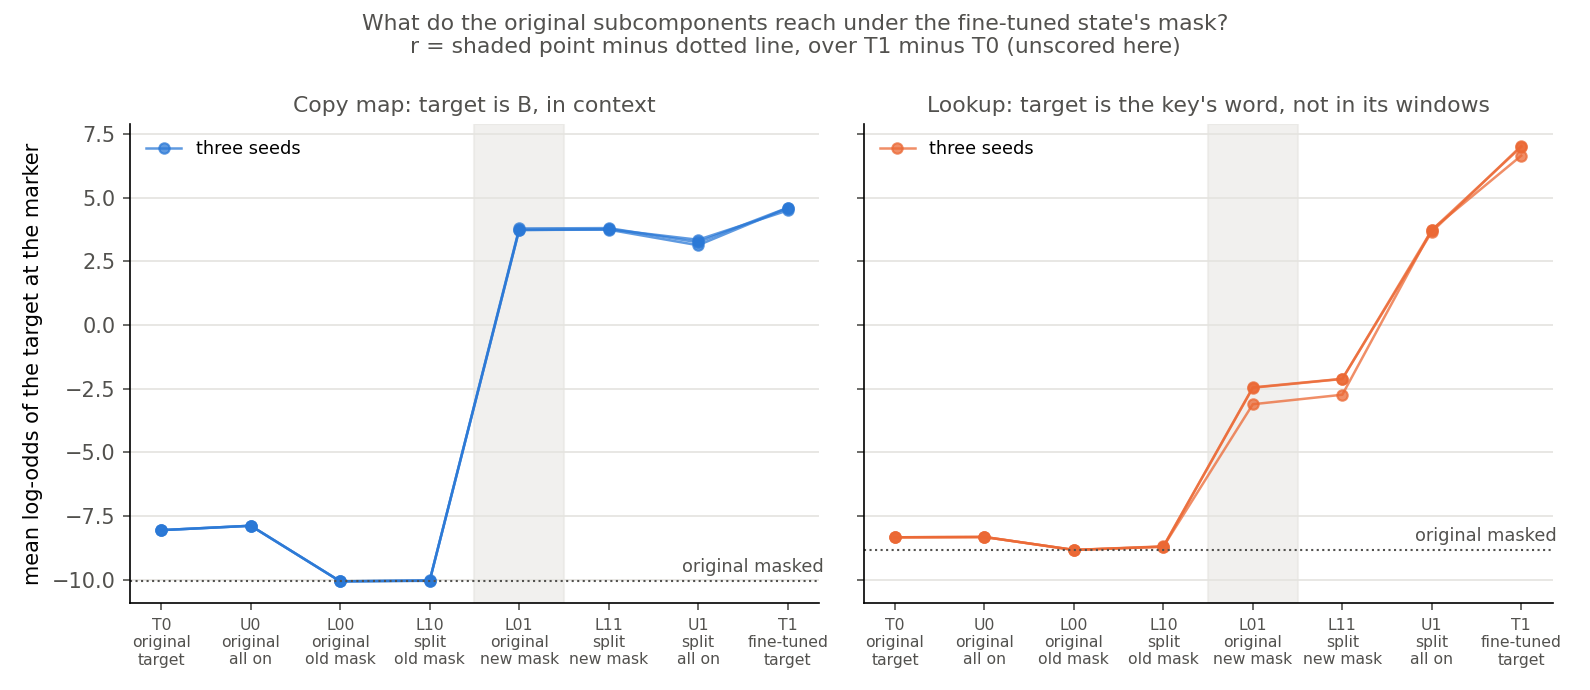

In [2]:
display(Image(filename=str(FIG / "cells.png")))

**Reading it.** On the copy map, the mask alone does everything; on the lookup it does not. On seed 0 the copy map's masked rise is 13.85 and the target's gain 12.66, so r is over 1. The shaded point and the next one are equal: $L_{01}$ is 3.79 and $L_{11}$ is 3.80. In plain words, the original subcomponents under the new mask already copy unseen Bs, and changing them adds almost nothing. On the lookup the masked model ends about 9.5 log-odds short of the target.

r over 1 is not meaningful as a share. It comes from a low start. The masked original sits 2.18 under the all-on original for B. The same masks cost the lookup's word only 0.51. Measured from $U_0$ instead, r is about 0.92, near E58's copy map at 0.85. So the excess over 1 is the low start, while the high reading survives it.

Does a target in context make r high whatever the mechanism? The saved numbers cannot say. The code shows no leak: the target column reaches no forward pass, and the old and new read paths matched exactly. The concern is conceptual. The original weights can write whatever a copying head attends to. So any mask that opens that path raises any in-context token, whereas the lookup's word is out of its own windows by construction. "Target in context" and "old mechanism" point the same way here. The mask also carries information from the fine-tuned activations, so $L_{01}$ is not purely old weights. Yet the lookup's word still rises 5.7 to 6.4 log-odds under the new mask with original subcomponents and no copying path. So either they hold part of the entry or the mask carries it, and r on an arbitrary map with no rule reads about 0.3 to 0.4, not 0. One test reads the copy state's mask for a different in-context token. Another is a map with its target in context that the head label calls new.

Update size separates the two maps as cleanly as r does. Under the same recipe at step 30, the copy map's updates are about 4.6 and the lookup's about 5.5, with no overlap. So size is a third live reading of the gap in r, beside mechanism and context. It may only be a proxy for how easy a map is, and this run cannot tell.

## Did the prior set r? Provisional, not scored

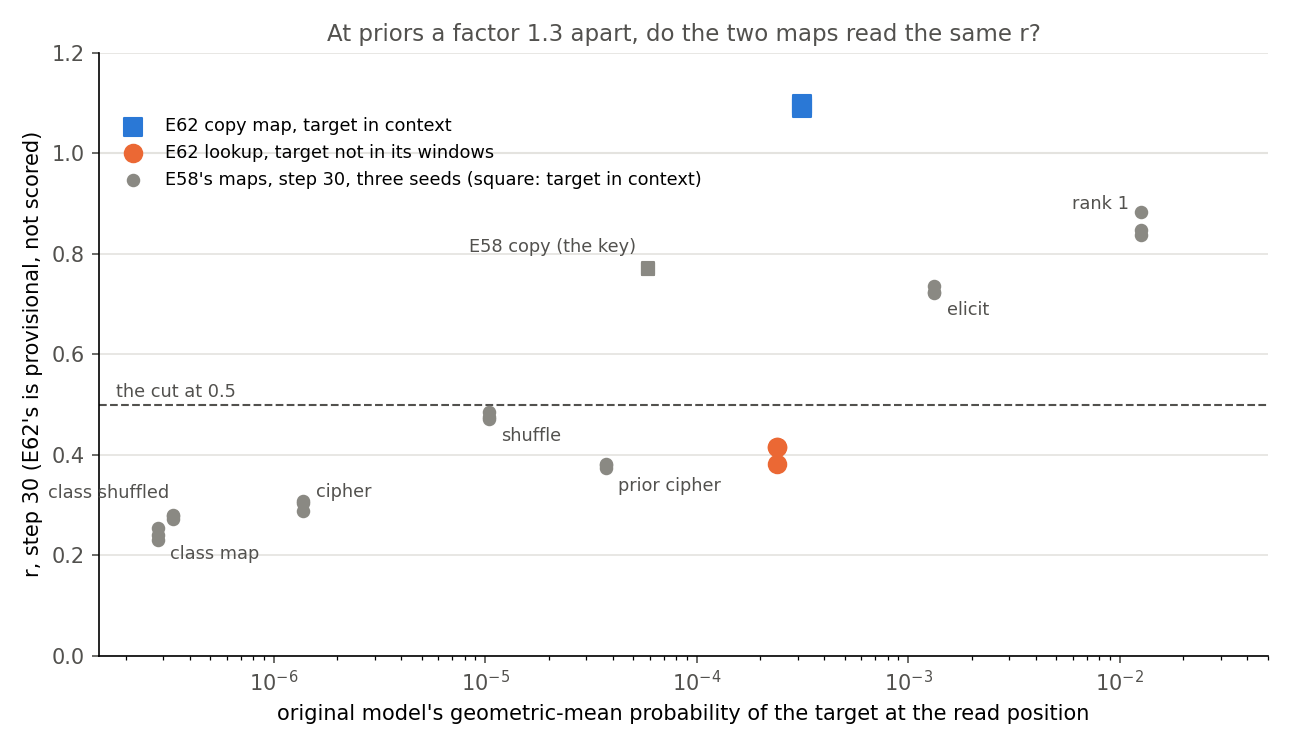

In [3]:
display(Image(filename=str(FIG / "r_prior.png")))

**Reading it.** Unscored, and only on geometric-mean probability on the read windows, the two maps are close in prior and far apart in r. The priors sit a factor 1.3 apart, and r reads about 1.09 and 0.40. The prior account predicted about 0.75 for both, and each map misses it by about 0.3 in opposite directions. The lookup sits on the prior cipher's level, well under elicit and E58's copy map. Across E62's lookup and E58's cipher and prior cipher, a factor of 170 in prior moves r by about 0.1. E58's shuffle reads 0.47 at a prior of 1.0e-5, above E62's lookup at 23 times that prior. With shuffle and class shuffled included, r spans about 0.2. Windows and key counts differ across these experiments, so that comparison is rough. The axis is one label over two measures: E58's points use its training windows, E62's its read windows.

This does not show that a prior account fails, for three reasons. The match holds on one measure only: on each seed's first batch the geometric-mean ratio is about 4 and the mean-probability ratio about 25. It is in-sample, since each word was selected from about 25,000 candidates on its key's few read windows. And the numbers match but not their kind. B's prior is 65 times its level with B absent, so nearly all of it comes from context, while a lookup word is out of its windows. E58's own pair, at r 0.38 and 0.77 a factor 1.6 apart, already showed the prior does not fix r at a small gap.

The same masks put B and the word 1.2 log-odds apart, which adds about 0.1 to the copy map's r.

The prior itself read 3.2e-4, three times the top of the filed band of 1e-4. The filed rules let that run on unflagged. It is 0.03% of the probability, far from W₀'s guess. So the cell is "old mechanism, answer weakly present" rather than the cleaner cell the band was drawn for.


## What we learned

`GOALS.md` asks whether post-training teaches new capability or strengthens old. Here the copying fine-tune runs partly through a head the original model already copies with. A lookup at the same marker, under the same recipe, does not use that head at all. Its update is about 19% larger and its gain about 21% larger. That is a causal difference with no decomposition involved. The share's size is near the filed bar and is measured from an original never read with the head off. Unscored, and only on geometric-mean probability on the read windows, the two maps are close in prior and far apart in r, by 0.69. Whether r reads mechanism stays open, with the target being in context and update size as live readings beside it. Size may only be a proxy for how easy a map is, and this run cannot tell. Every high-r map among these ten has a target the original components can already produce: W₀'s own guess or a token in context. A new circuit built from old pieces reads as elicited to VPD. Head ablation cannot split that from a redirected old circuit either, so every claim here holds only at the level of heads and subcomponents.


## How compelling is the evidence

One model, one marker, 32 keys, 200 read windows, three seeds, read at step 30 only. Row noise on the share is 0.016; the seed range is 0.09. The share is blind to a fine-tune that keeps the head's key and value paths with a new query, and to other heads it recruits. Downstream compensation after ablation, the hydra effect of McGrath et al. 2023, would make it an underestimate. It is also measured against an ablated original that was never read. Under the fine-tuned states no other head crosses the prefix bar, on repeated random sequences only.
r is blind to which subcomponents the mask changes. No same-size random update was read at this target, and on Qwen a random change read r 0.99.

## Surprises

- A narrow miss: seed 2's share read 0.47 against 0.5. It stands as a miss.
- r over 1 on the copy map, a case the plan's table did not foresee.
- The copy map was the fast learner. Its read windows reach a probability of about 0.89 at step 10, on Bs it never saw, against about 0.55 for the lookup's trained words. We had leaned the other way.
- Head `(1,1)` costs the lookup almost nothing. The advice kept it out of the head set on the reasoning that the lookup needs it too, which this does not support.

## What next

E62 Amendments 2 and 3 have since run, in their sections at the end, and Amendment 3's "What next" replaces this one. Nothing else is proposed here, and the other open reads are listed there. What would change the most beyond it: a map with its target in context that the head label calls new. If that reads high, r is reading the context rather than the mechanism.


## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| a_heads | one or more copying heads, necessary, others harmless | top-1 under the set < 0.3, median other > 0.7 | head (2,4); 0.0095; 0.79 | holds |
| b_prior | B's prior in the band | [1e-6, 1e-4] | 3.15e-4 | **misses**, known before this run; runs on |
| b_match | priors matched | ratio ≤ 2 | 1.32 | holds |
| path | new target path equals the old | r within 0.03, cells ≤ 1e-4 | 0 difference | holds |
| c_finetune | specific gain reaches 5.148 | by step 300 | 20.0 to 22.4 at step 30 | holds |
| d_label, copy | share ≥ 0.5 on every seed | old | 0.563, 0.545, 0.471 | **misses on seed 2** |
| d_label, lookup | share ≤ 0.2 | new | 0.000, −0.004, −0.003 | holds |
| d_label, floor | median other head < 0.15 | | 0.011 to 0.052 | holds |
| d_label, absent | B-absent ratio ≤ 0.2 | | −0.62, −0.59, −0.62 | holds |
| d_label, specific | lookup specific share ≥ 0.5 | | 1.44 to 1.46 | holds |
| d_broken_pair | broken ratio ≤ 0.5 | sets `pair_ignored` | 0.40, 0.34, 0.54 | **misses on seed 2** |
| e_r | r separates the maps | scored only if the label holds | copy 1.09 to 1.10; lookup 0.38 to 0.42 | **not scored** |

Verdict as filed: `copy_not_elicitation`, `r_scored` false.

## Departures from the literature

- **Ablation.** Olsson et al. 2022 zero-ablate a head, on small models. We mean-ablate over ordinary text, one vector per head, as approved. Zero ablation was not run.
- **Prefix score.** Their recipe uses 10 sequences of random tokens without the most and least common. We use 48 sequences of word-like tokens, with cut-offs and a bar fixed here, since they give none.
- **Copying score.** They also require one for an induction head. We use prefix matching and the causal control.
- **Capability.** Jain et al. 2024, Definition 2, takes a linear readout as the capability. We take a head set with the user's causal requirement.
- **Thresholds.** The cut of 0.5 is this project's convention and the prior match of 2 is chosen here. Neither is published.

The report's list has the rest.


## Not run

E62 Amendments 2 and 3, head ablation inside the masked forward with the masks frozen and then recomputed, have since run: see their sections below, which list what is still not run.

The full list is in `reports/analyses/2026-11-02_analysis_e62-copying-heads.md`. It holds the original model's own log-odds under the head, both heads off together and the share at later steps. It also holds the copying head's attention at the marker, ablated reads on pair-broken windows, and downstream compensation after ablation. So too r read for other in-context tokens or a random update, and an in-context map the label calls new.

**Provenance.** `experiments/induction_cue/results/run.json`, job 48541, NVIDIA L40, MATS debug, about 3.5 minutes, $0. Code `experiments/induction_cue/run.py`, `src/commute/copying.py`. Figures `experiments/induction_cue/plot.py`. Independent check: `reports/reviews/2026-11-02_review_e62-check.md`.


# Amendment 2: does the mask's gain on the copying map go through the old copying head?

**The answer.** Untested: this read could not tell, so the stop the plan names is held, not taken. With the old copying head switched off and the masks frozen, the target model mostly stops producing the copied token, while the masked forward still produces it. But the masks were written with the head on and are the update's only way into that forward, which also never holds the fine-tuned head. Amendment 3, recomputing the masks with the head off, has since run and found that the masked gain falls: see its section below.

## What we were trying to test

Nothing was trained. We re-read the six saved step-30 states on the same 200 windows. r is the masked gain over the target model's gain, where the masked gain is what the original subcomponents reach under the state's mask minus what they reach under W₀'s mask. The new step replaces head (2,4)'s output by its mean inside that masked forward, with the masks held as they were read with every head on. If the masked gain falls by the share the target model's gain falls, r and the head label read the same thing.

Beside that: W₀'s own fall under the head, which E62 discarded, both circuit heads off together, the gain with the pair broken, and r with each update scaled to the other map's size. Head (3,5) is the reference head, and the zero update is the do-nothing reference, reading exactly 0. The control ran first and alone: top-1 on repeated sequences through the masked forward with every mask at 1 should collapse under the head.

## What we expected, and why

The lean was that the masked share would sit within 0.092 of the target share, a tolerance taken from E62's seed range. At W₀ the masked forward was expected to show the target model's lean of about 1.57 log-odds and lose most of it with the head off. The plan also leaned towards the second head adding nothing, the pair-broken gain surviving the head, and size not explaining the gap in r.

## Does the masked gain fall with the head?


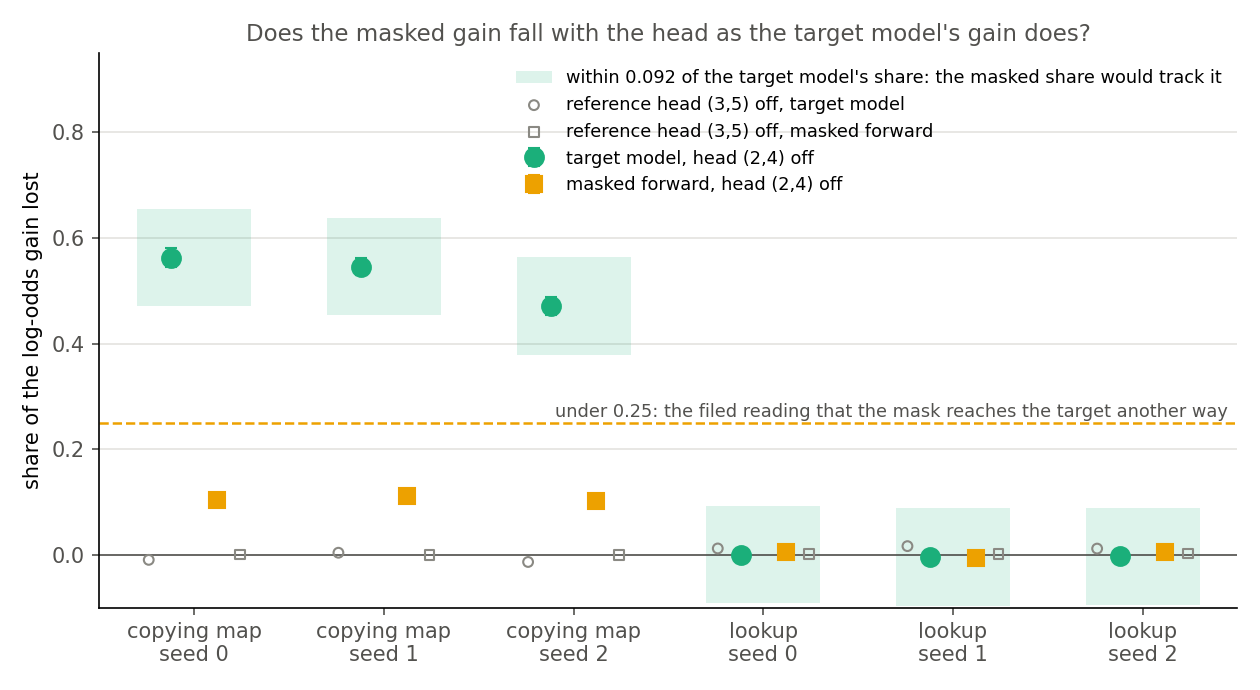

In [4]:
display(Image(filename=str(FIG / "amend2_share.png")))


**Reading it.** No, with the masks frozen as read with the head on; what happens when they are not was not read. The target model loses 0.47 to 0.56 of its gain, and the masked forward loses 0.10 to 0.11. Those shares sit far outside the shaded tolerance on all three seeds, with a row sd of 0.006. Each is under the filed 0.25, which is the filed label that the mask reaches the target another way. The label stands, and it claims more than this read shows. At the mean log-odds, the target model's probability of the copied token falls from 0.99 to between 2.4% and 7.1%, and the masked forward's from 0.98 to about 0.9. The lookup reads about 0 in both forwards, an agreement with little power.

## Does the control support the masked share?


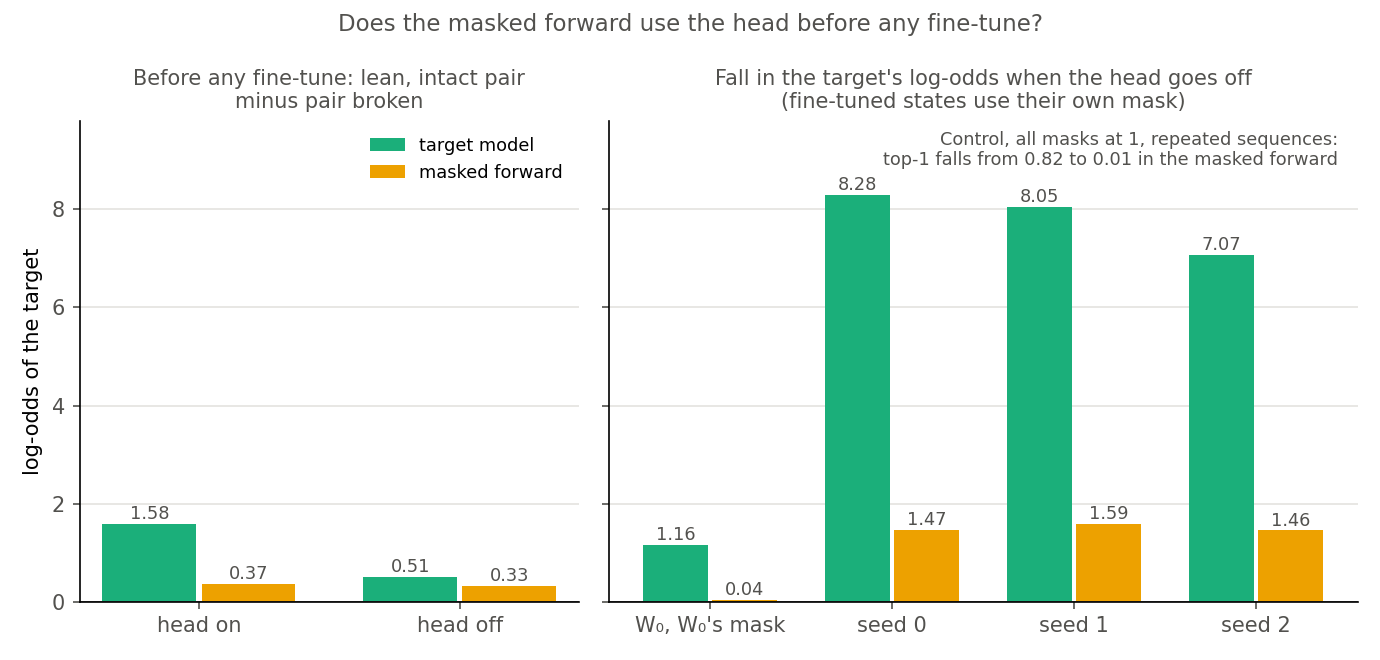

In [5]:
display(Image(filename=str(FIG / "amend2_w0.png")))


**Reading it.** Only partly. The control shows the hook works and that the head matters with every mask at 1, where top-1 falls from 0.82 to 0.01. It cannot show the head matters under the masks actually used. Under W₀'s mask, the lean reads 0.37 against the target model's 1.58, and the head off keeps nearly all of it. The head's removal moves the target by 0.04 log-odds, against 1.16 in the target model. The state's mask raises that to about 1.5, still about a fifth of the target model's fall on the same state.

That rise does separate the maps, unfiled. Net of W₀'s mask the head moves the masked forward by about 1.5 log-odds on the copying map and about 0.03 on the lookup, the label's order. It is small against a gain of 13.8 and the masks are frozen, so it is a pointer and not a pass.

**The frozen mask is the main limit.** The masked gain uses W₀'s subcomponents with Δ out and no target weight left, so the update can reach it only through the mask. Γ reads the inputs of all 24 matrices over the whole row, including head (2,4)'s output and everything downstream of it, so the mask can carry what the head wrote. So this read asks only whether the head still matters given masks already written with it on.

Four accounts fit. The masks may close the head's way, a statement about what masks keep. The update's masked gain may really go elsewhere, with the head's way open. The head may act through the mask itself, which frozen masks cannot see. Or the fine-tune's use of the head may lie in its weight change, a redirected query. The masked forward holds only W₀'s q, k and v, so it may be unable to reproduce that use, and the filed label would then fire on reuse. A masked share matching the target's would have needed an elicitation done wholly by the mask.

The saved cells speak to the state's mask, though not at the head. With every mask at 1 the least-squares split's change carries about 11 log-odds of the update. Under W₀'s mask or the state's, on the copying map, it carries 0.01 to 0.04. So r's forward is cut off from the update's weights by construction.

## Was "about half" a large underestimate?


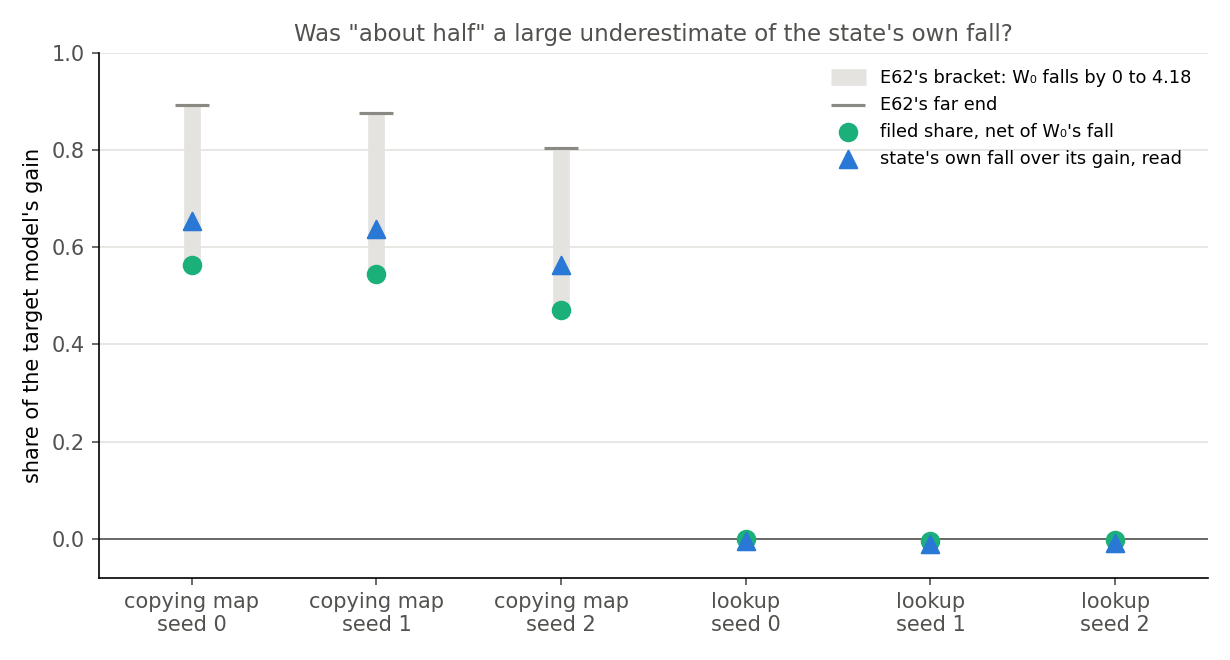

In [6]:
display(Image(filename=str(FIG / "amend2_own_fall.png")))


**Reading it.** Not on the log-odds scale. W₀ itself falls 1.16 log-odds under the head, so the state's own fall is 0.56 to 0.65 of its gain, well inside the bracket reaching 0.80 to 0.89. In probability the behaviour still mostly goes, because a fall of 7 to 8 from a level near 4.5 crosses zero. The own fall holds W₀'s 1.16, which is there before any fine-tune, so the fine-tune's reading stays the net share of 0.47 to 0.56.

## Does a second head add to the first?


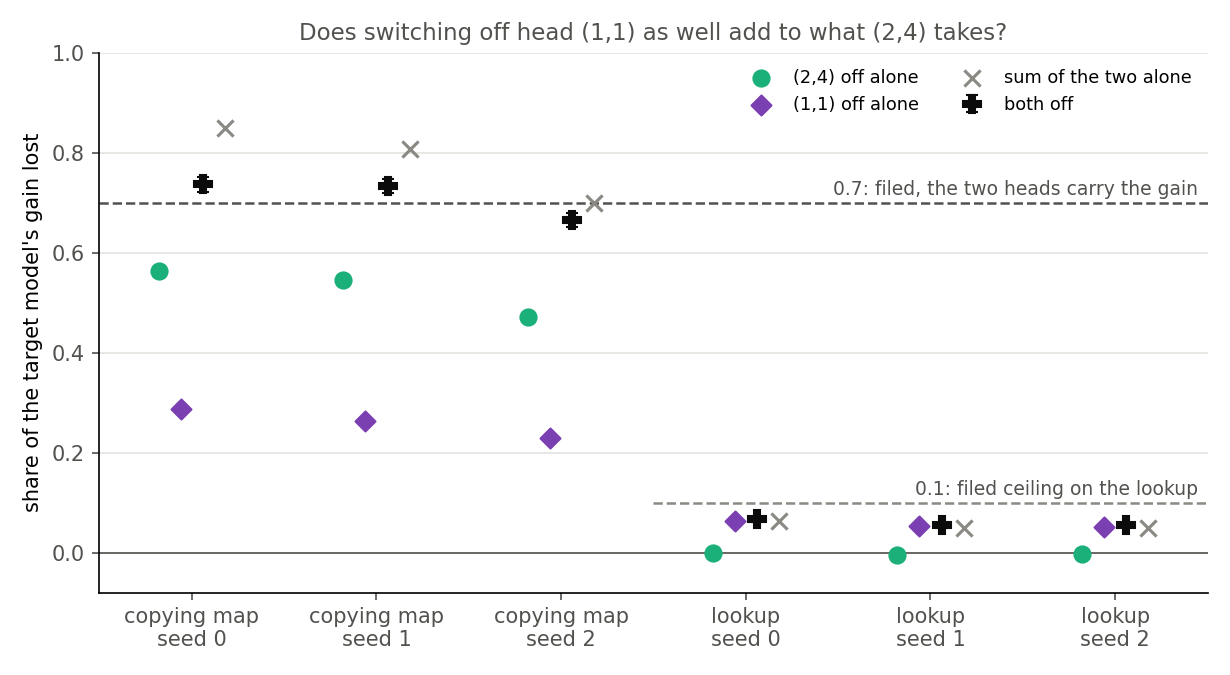

In [7]:
display(Image(filename=str(FIG / "amend2_two_heads.png")))


**Reading it.** Yes on net shares, and only there. Both heads off takes 0.67 to 0.74 of the copying map's gain, so the net share rises by 0.17 to 0.20. Strict series is refuted, since head (1,1) off does something with (2,4) already off. It does not follow that the fine-tune's copying leans on (1,1). The share is net of W₀ under both heads, a level the run did not save, and both heads off also cost the lookup 0.82 to 1.02 log-odds. Seed 2 sits just under the filed 0.7, so the filed reading over seeds is mixed.

## Does the pair-broken gain survive the head?


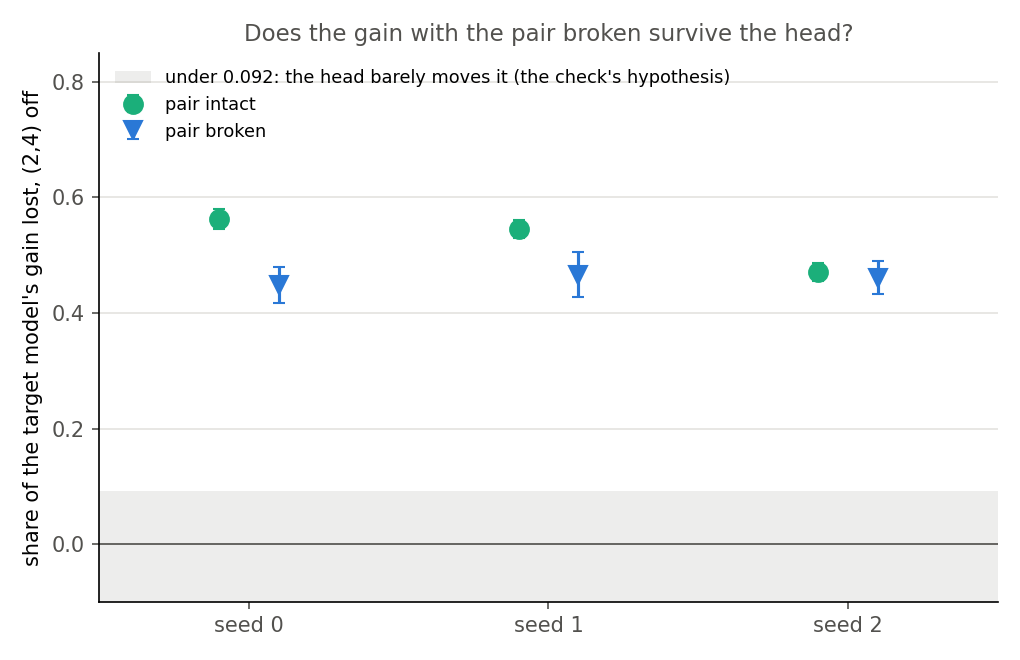

In [8]:
display(Image(filename=str(FIG / "amend2_broken.png")))


**Reading it.** No, so the independent check's hypothesis fails. It predicted the head off would barely move this gain, and the gain loses 0.45 to 0.47 on all three seeds. The looser copying goes through the head at about the rate the prefix-matched gain does. The filed reading across seeds is mixed only because seed 0's intact share is high. Unfiled, pair dependence also survives the head: intact minus broken loses 0.48 to 0.64 of itself, so something outside this head now computes the pair.

## Does update size explain the gap in r?


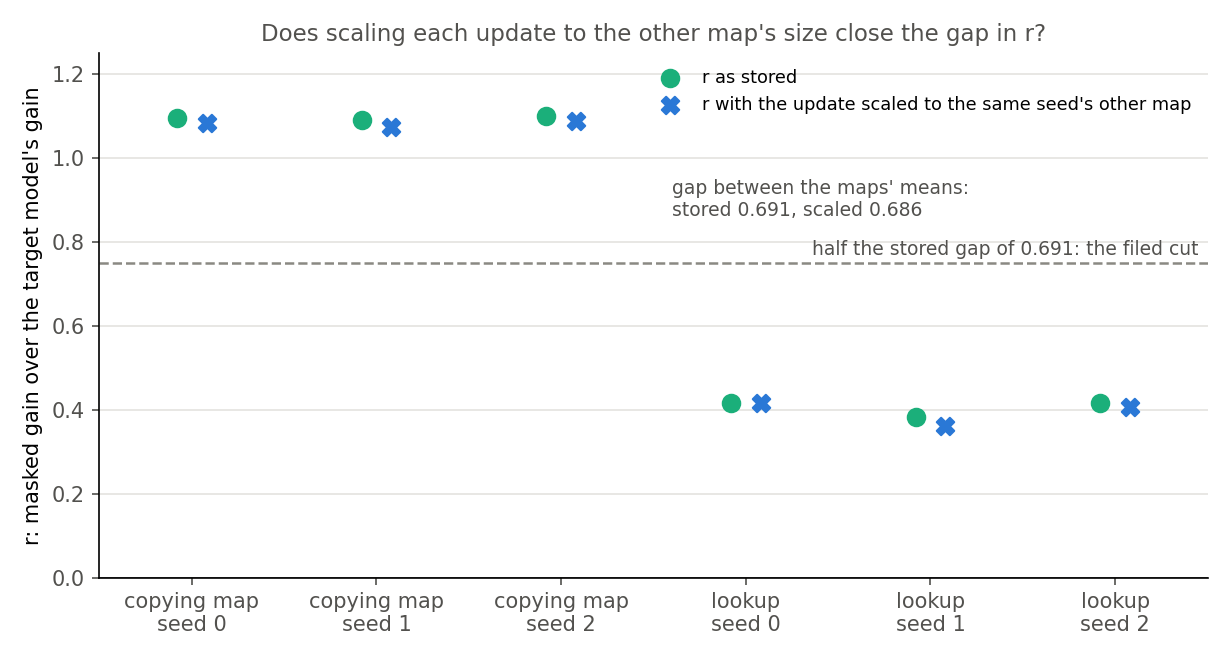

In [9]:
display(Image(filename=str(FIG / "amend2_size.png")))


**Reading it.** No, over the range tried. Scaling each update to the same seed's other map, a factor of about 1.19 either way, moves the gap in mean r from 0.691 to 0.686. A scaled update is not a shorter fine-tune, and this does not separate a map's size from how easy the map is.

## What we learned

At the level of heads the answer is unchanged in size, with W₀'s fall now read: the fine-tune's net share under the head stays 0.47 to 0.56, its looser copying uses the head too, and the lookup does not. For `GOALS.md` that favours reuse of an old circuit over a new capability on this map. Whether the decomposition reads the same thing was untested by this read, on one map, one marker, step 30. Amendment 3 has since read it with the masks recomputed. With the masks frozen most of the masked gain survives the head. But that read held the update's only way in fixed and never held the fine-tuned head. r gives no mechanistic reading here. Its forward is cut off from the update's weights, and it is blind to reuse by a redirected query.

**Granularity limit.** A new circuit built from old pieces reads as elicited to VPD, and a redirected query still counts as reuse. Every statement here holds at the level of heads and of VPD's subcomponents.

E58's other maps keep their numbers: how much of the gain the original subcomponents reach under the state's mask, and how maps differ at step 30. Their high r cannot be read as an old mechanism, since none has a head label. Nor does this show r fails there, as this map has the largest low start of ten.

## How compelling is the evidence

One model, one marker, three seeds, step 30. The masked share's row sd is 0.006, against a gap to the target share of 0.37 to 0.45. All re-reads matched. The masked share is blind to the head's effect on the mask, which is the update's only way in, and to the fine-tuned head. It is also blind to which subcomponents carry the gain and to a mean that may sit off the masked forward's distribution. That mean passes through different masks in the two cells, so it does not cancel. The reference head has a target share near 0 on the copying map, so its low masked share says little alone. The zero update reads 0 under any hook, so it is a do-nothing reference and not a control.

## Surprises

**Something unexpected happened that I cannot explain.** The lean was a masked share tracking the target share, and it reads about a fifth of it. The masked forward at W₀ was expected to show a lean near 1.57 that the head removes, and it shows 0.37 that the head barely moves. The rise under both heads and the pair-broken gain's fall also went against their leans.

## What next

Written before Amendment 3 ran, and overtaken by it: the masked gain fell, so the stop did not fire, and its section below replaces this paragraph. One correction to what was said here. A fall near the target share was said to point to r reading the head through the mask. It shows less: the mask follows the head, which is not the same as r reading the mechanism, because Γ reads the fine-tuned model's own activations.

The plan's tree reports r as weaker than mechanism and stops the 67M copy work. That stop was held until Amendment 3 read back: Γ recomputed with the head off. Γ never trained on a head's slot held constant, so that fall needs the lookup, head (3,5) and W₀'s recomputed mask beside it, and the first two should not fall. If it barely falls, the stop can be taken, with the redirected query still open. If the head's output under the state's mask is near its mean, or its slot is closed, the statement becomes one about what masks keep.

## Scorecard

| row | claim | read | verdict |
|---|---|---|---|
| 1 | hook works with every mask at 1 | 0.818, 0.0095, 0.698 | `pass` |
| 3 | masked share against target share | 0.103, 0.112, 0.103 | `mask_reaches_b_another_way`; lean wrong; stop held |
| 3 | lookup | 0.005, −0.007, 0.005 | `within` |
| 4 | state's own fall over filed share + 0.092 | 0.655, 0.637, 0.564 | `in_between` |
| 5 | both heads, copying map | 0.737, 0.734, 0.666 | `in_between`; lean, filed conditional on series, not met |
| 6 | pair-broken share | 0.449, 0.466, 0.461 | `in_between`; lean wrong |
| 7 | swapped gap | 0.686 against 0.691 | `size_does_not` |

Row 4's `in_between` carries no information: own fall minus filed share is 0.0919, 0.0920 and 0.0927 against a tolerance of 0.092, a fourth-decimal split. The report has the full table and the other rule notes.

## Departures from the literature

Olsson et al. 2022 zero-ablate a head, on small models; we mean-ablate, as approved for E62. Ablation inside a decomposition's masked forward has no source we know of, and the masks are held fixed. No threshold is published.

## Not run

First, the reads that would separate the four accounts, each $0 on the saved states: Γ recomputed with the head off, which Amendment 3 has since run; the head off on the split subcomponents under the state's mask and with every mask at 1, with its attention; an own-mask mean and zero ablation, for removal against injection; how much of the head's slot in o_proj passes under each mask; the masked forward's head output against its mean; the head's attention at the marker in the masked forward; the head off with every mask at 1 on the read windows; all 24 heads off singly in the masked forward; both heads off in the masked forward. The full list is in `reports/analyses/2026-11-02_analysis_e62-amend2-masked-head.md`.

**Provenance.** `experiments/induction_cue/results/amend2.json`, job 48698, NVIDIA L40, MATS debug, about 4.5 minutes, $0. Figures `experiments/induction_cue/plot_amend2.py`.


# Amendment 3: with the masks read again with the old copying head off, does the masked gain fall?

**The answer.** Yes, so the plan's stop does not fire. On this one map at step 30 the masked gain loses about two thirds of itself with the head off, both in the pass the masks are read from and in the masked forward. The lookup loses nothing. That shows the masks follow the head. It does not show that the subcomponents they open carry the old mechanism, because the mask function reads the fine-tuned model's own activations. And before any fine-tune, switching the head off barely moves the unchanged model's masked forward, which remains unexplained.

**This reverses what Amendment 2's filed label implied.** The label stands as filed, as a low share with frozen masks. Its name, that the mask reaches the target another way, is no longer a fair summary: the masks are not independent of the head. The account behind it, that other subcomponents carry the gain inside the masked forward, is not removed, and it can hold together with the masks following the head.

## What we were trying to test

Amendment 2 switched the head off inside the masked forward and lost a tenth of the masked gain. But every target weight in that forward is replaced, so the update can arrive only through the mask, and that read froze the mask. So nothing was tested, and the stop was held.

Here nothing was trained. The same hook replaces head (2,4)'s output by its mean in the target-model pass that Γ reads, and again in the masked forward, at W₀ and at the six saved step-30 states. We compare three shares of gain lost, each net of W₀: the target model's, the masked forward's with frozen masks, and the masked forward's with recomputed masks.

Each reference tests one alternative. The lookup under the same head has the same depth on a map the head does not carry, so it should not fall even if Γ reacts. Head (3,5) checks that switching off some other head does not break the masks. W₀'s recomputed fall sizes what Γ's reaction alone does to a net share. Any of those ten over 0.15 would void the reading. On the copying map that bar is over the target model's own W₀ fall, so W₀'s reference could hardly fire. A third read gives the mean mask on the few subcomponents that read mostly one head's slot in block 2's `o_proj`.

## What we expected, and why

The prediction was weak: the share would not stay under 0.25, since Γ's masks follow activations that the head moves a long way. Where it would land was not predicted. The lookup was expected near 0. If the masks close the head's way, its slot was expected closed at W₀; the other accounts filed no expected value.

## First, the anomaly: what does the head do in W₀'s masked forward?


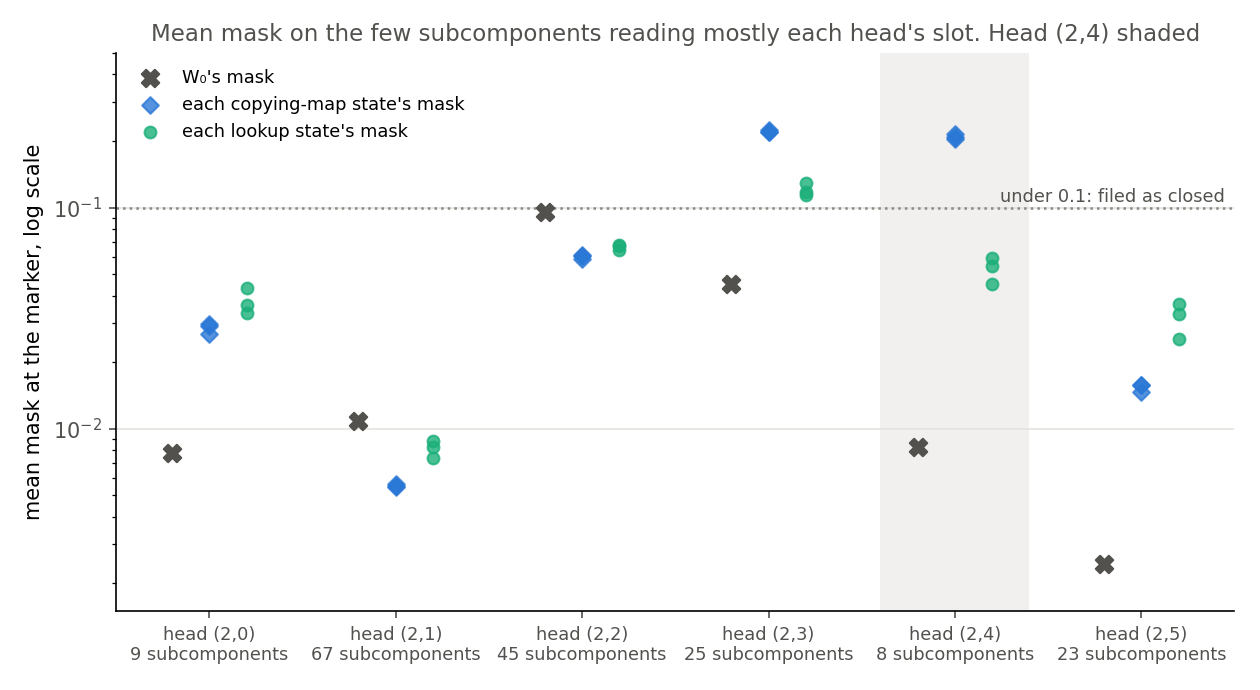

In [10]:
display(Image(filename=str(FIG / "amend3_slot.png")))


**Reading it.** The measurement that stands is W₀'s frozen fall. With the masks read with every head on, switching the head off moves W₀'s masked forward by 0.04 log-odds, against 1.16 in the target model. Whether W₀'s mask shuts this head is not shown. The figure covers eight subcomponents holding 5.4% of the slot's read weight, among the 524 alive in that matrix, and the rest was not read.

Those eight read nearly shut at W₀, with a mean mask of 0.008. That fits Amendment 2's low lean, the intact pair's log-odds over the broken pair's, though nothing shows that it causes it. They read 0.20 to 0.22 at the copying states and about 0.05 at the lookup's. So the sample also opens five- to seven-fold on a map that does not depend on the head, and an opening does not imply dependence. All six samples sit under the filed bar at W₀, and head (2,3)'s opens at the copying states as far as this one. The columns also cover unequal parts of their slots, 5% to 35%, so they do not compare the heads' output.

**What fits.** The head's removal barely moves W₀'s masked forward, and the sample reads nearly shut. The lost lean also fits as arithmetic: the masked forward's 0.37 sits near the target model's lean with the head gone, 0.51.

**What is not explained.** Why the head barely moves that forward when the original model's copying runs through it, and whether Γ shuts the head at all. Whether a closure causes the low lean, as nothing re-opened the slot. And about 0.85 log-odds of the low start that a closed head could not account for.

**What rests on it.** The large, map-specific fall below does not: W₀ enters it only as a subtraction of 0.03 of the gain. The label "above the target's" rests on it by half. The reading that the state's mask draws on a mechanism W₀'s masked forward has rests on it wholly. It is blocked, because how much of the head's output W₀'s mask passes was not read.

## Does the recomputed mask move W₀?


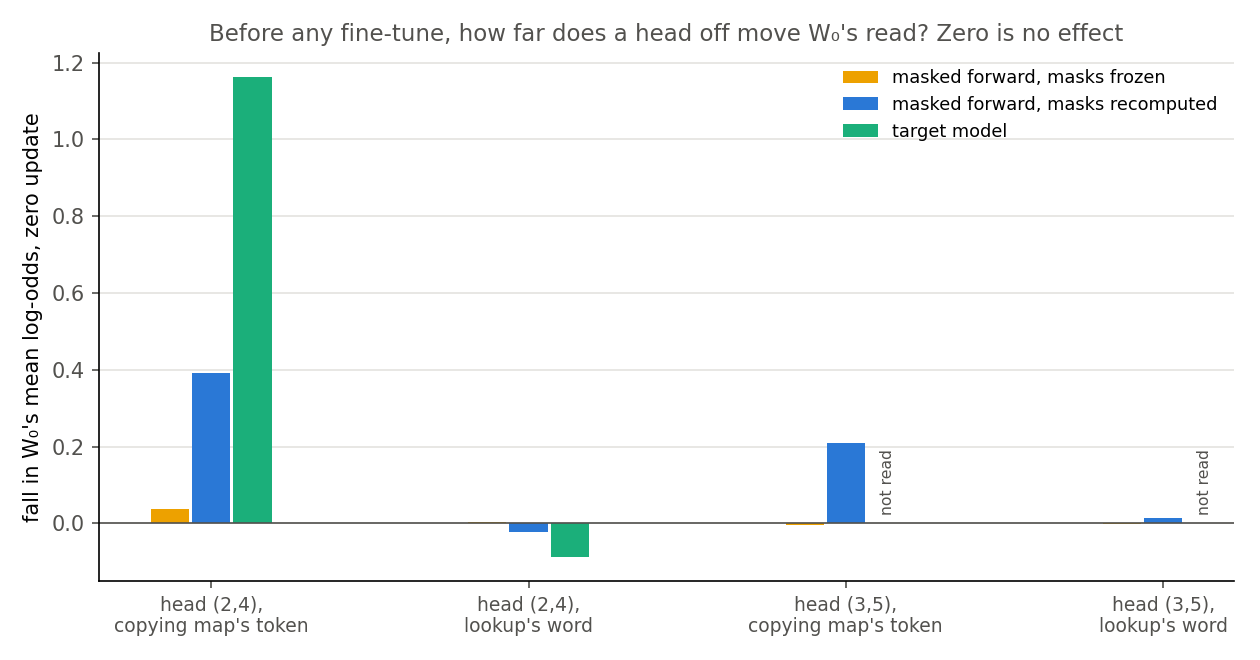

In [11]:
display(Image(filename=str(FIG / "amend3_w0.png")))


**Reading it.** Yes, a little, and not very specifically. W₀'s fall on the copied token rises from a frozen 0.04 to a recomputed 0.39, under the target model's 1.16. Head (3,5) reaches 0.21 there, about sixty times its frozen size. So Γ does not tolerate an ablation silently, and at W₀ it barely tells the two heads apart. A head that barely moves the masked forward is also not hidden from Γ, which reads the target-model pass that the hook edits. On the share scale this stays at most 0.03.

## Does the masked gain fall with the head when the masks are recomputed?


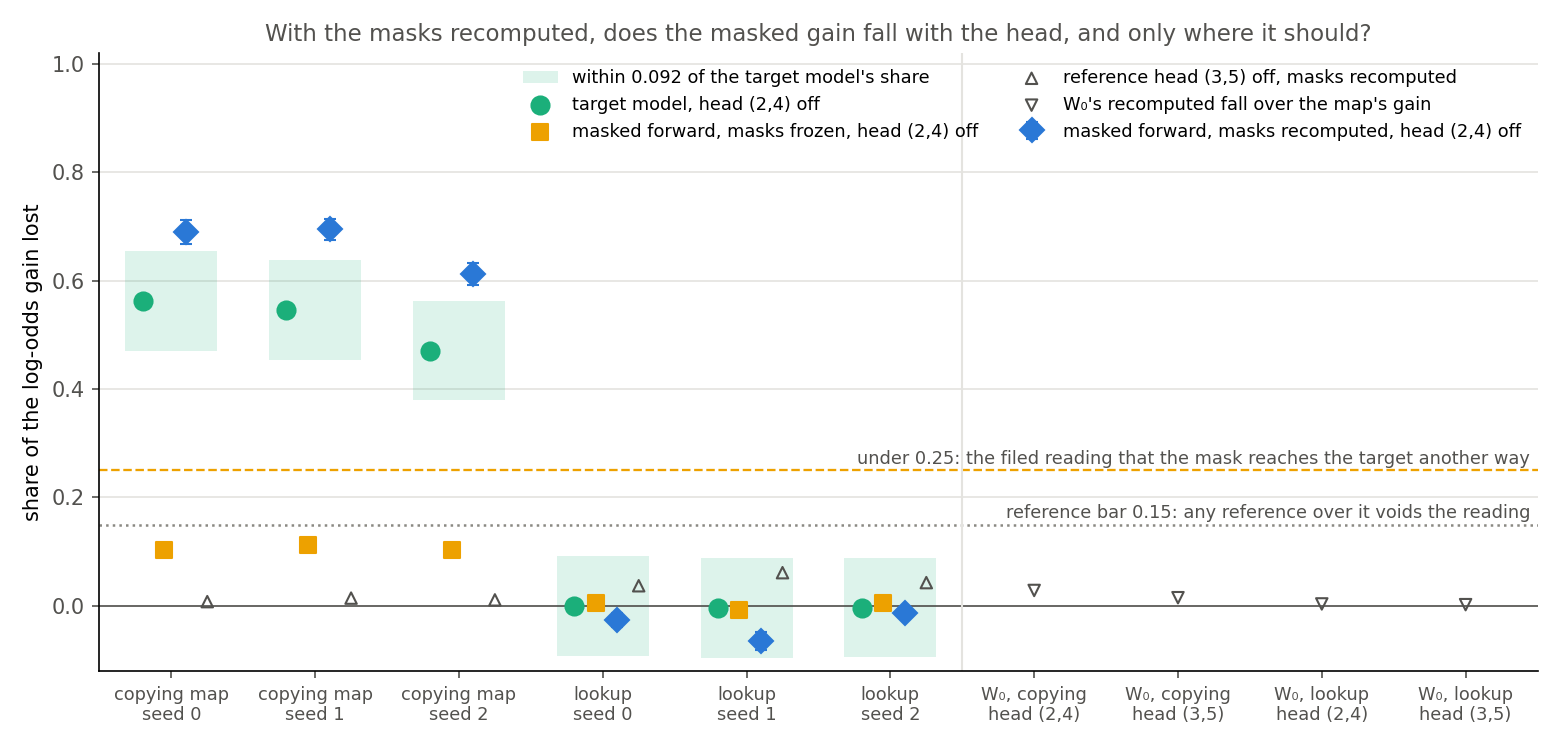

In [12]:
display(Image(filename=str(FIG / "amend3_share.png")))


**Reading it.** Yes on all three seeds of the copying map, and not on the lookup. The recomputed share reads 0.61 to 0.69. Frozen masks read 0.10 to 0.11, and the target model 0.47 to 0.56. The lookup reads −0.06 to −0.01, within tolerance of a target share near 0, and all ten references are at most 0.06. The gain is cut, not erased: about a third survives, against about half in the target model. At the mean log-odds the masked forward's probability of the copied token falls from 0.98 to under 1%.

## What does the fall mean?

**The reading is narrow: on this map, at step 30, the masks producing the gain depend on this head's output.** It is not "r reads the label's mechanism", for three reasons.

Γ takes the head's output as input, so replacing it can move any mask Γ computes from it, whether or not those subcomponents carry the behaviour.

Γ also reads the fine-tuned model's later activations. With the head off, that model stops producing the copied token and those activations change. So a share that tracks the target model's is what simple inheritance predicts, whichever subcomponents open.

In the masked forward itself the head's output carries little. The frozen share is about a tenth, on masks whose sampled slot reads about 0.2. So most of the fall needs the masks to change.

**How strong is the specificity?** Strong against Γ simply breaking whenever a head is replaced: the same hook and windows leave the lookup's gain of about 6 log-odds intact, and head (3,5) costs the copying map at most 0.014 of its gain. It is weak beyond that. In both references the target model does not use the head, so a break that scales with how much the head writes would pass them. Inheritance predicts them too, and so does the fact that the copying map's target sits in its own context and the lookup's does not.

**The four accounts from Amendment 2 are not exclusive.** Γ may use the head's output to choose masks, and those masks may then let other subcomponents write the copied token.

| account | status | evidence |
|---|---|---|
| The masks close the head's way | unread beyond a 5% sample | sampled slot 0.008 at W₀, about 0.2 at the copying states |
| The gain goes elsewhere in the forward | live | frozen share about a tenth |
| The head acts through the mask | supported as "masks react"; inheritance and an off-distribution break not separated | recomputed share 0.61 to 0.69 |
| The fine-tuned head is not in the forward | untouched | no read |

## What does "above the target's" mean?


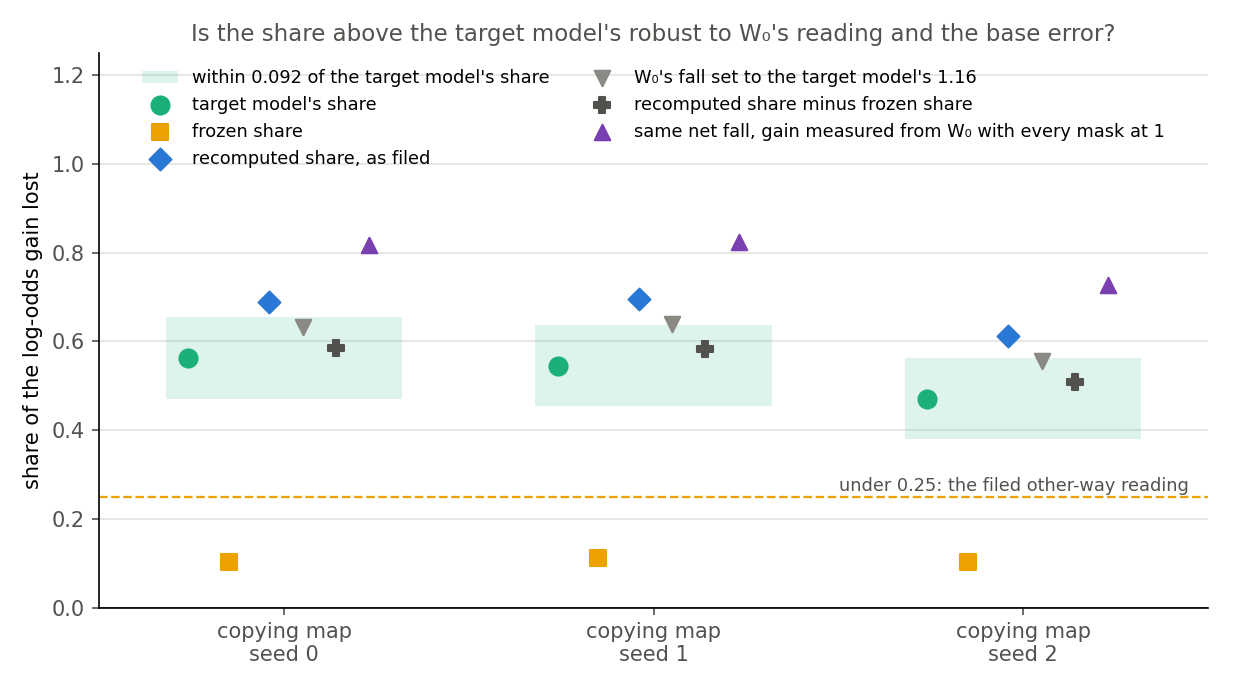

In [13]:
display(Image(filename=str(FIG / "amend3_excess.png")))


**Reading it.** Read it as "at least as much as the target model's", not "more". The filed label is above on all three seeds, by 0.13 to 0.15. But half of that is one subtraction: the target model nets off W₀'s fall at 0.092 of its gain, the masked forward at 0.028. The states' own falls sit within tolerance of each other. With W₀'s fall set to the target model's, two seeds fall inside the band and one sits 0.001 outside it. Subtracting the frozen share also lands about on the target share, unfiled, and assuming the two add. A mean-ablated head and Γ off its distribution could inflate the share as well, and neither was separated. Every recomputed reading stays far above 0.25, and measuring the gain from every mask at 1 raises the share to 0.73 to 0.82. So the fall holds, and "more" does not.

## What we learned

The target-model shares were not re-read, so the head-level picture is unchanged: for `GOALS.md`, reuse stays favoured over a new capability on this map. For the decomposition there is one new fact, that the masks producing the gain depend on this head, and on the lookup they do not. So r on this map is not unrelated to the head. That does not remove the account that other subcomponents carry the gain in the masked forward; both can hold. And it follows the head through a function reading the target model's activations, in a forward that holds neither the update's weights nor the fine-tuned head. On the unchanged model, the head barely moves that forward. That gives no independent evidence of the old mechanism. So the plan's next step, the Qwen table, does not follow from this verdict either.

**What survives from Amendment 2's check.** The masked forward never holds the fine-tuned head, which here enters only as a signal to the masks. The base error stands: $L_{00}$ sits 2.18 log-odds under W₀ with every mask at 1, and part of the gain may be the state's mask opening what W₀'s mask keeps low. Target in context still goes with old mechanism on this map.

**Granularity limit.** A new circuit built from old pieces reads as elicited to VPD. This holds at the level of VPD's subcomponents and heads.

**E58's other maps** keep their numbers. They have no head label and no recomputed read. If the masks inherit the target model's dependence, a high r would not diagnose reuse there either. This does not show that r fails there, and the low r of the cipher and class maps is untouched.

## How compelling is the evidence

One model, one marker, 32 keys, three seeds, step 30. The recomputed share's row sd is at most 0.022, and the gap to the frozen share at least 0.51. The frozen path reproduced Amendment 2 with difference exactly 0. There is no positive control, as no state is known to depend on a head through Γ. The share is blind to which of Γ's inputs carries the reaction, to removal against injection, to which masks moved and to the fine-tuned head. The slot read covers 5.4% of the head's read weight and was made with every head on, so how replacing the head moves those masks is an inference. The recomputed share's row sd treats windows as independent though they share keys, so the seed range of 0.08 is the better guide.

## Surprises

**Something unexpected happened that I cannot explain.** The original model's copying runs through this head, and at W₀ switching it off barely moves the masked forward. A sample of the subcomponents reading it reads nearly shut. This blocks any reading that the state's mask draws on a mechanism W₀'s masked forward has. Also: the share landed above the target's, a verdict the plan named no consequence for; and head (3,5) moves W₀ sixty times its frozen size.

## What next

1. Which of Γ's inputs carries the fall: masks recomputed with the head on in the forward, then Γ with only the slot edited, then only the later inputs. If the later inputs alone carry it, the masks inherit the target model's behaviour.
2. A positive control: target share beside recomputed share for all 24 heads on both maps. If the share tracks whichever head, head dependence through the masks is no evidence of reuse.
3. A weighted slot read: how much of the head's output passes under each mask, over all alive subcomponents. Then re-open the slot by slot share, not just the eight, reading the lean. If it returns, the anomaly is explained at the slot and the blocked reading can be tried.

Each is $0. The stop is the lead's call, with the user told of the reversal.

## Scorecard

| row | claim | read | verdict |
|---|---|---|---|
| 1 | head off reaches Γ as filed; frozen path re-reads | status pass; difference 0 | holds |
| 2 | recomputed share against target share, copying map | 0.689, 0.695, 0.612 against 0.563, 0.545, 0.471 | `head_more_than_target`; weak lean holds |
| 2 | lookup | −0.027, −0.065, −0.013 | `within` |
| 2 | ten references under 0.15 | at most 0.061 | no `floor_high` |
| 3 | head 4's slot at W₀ | 0.0083 | `closed` |

## Departures from the literature

Olsson et al. 2022 zero-ablate a head, on small models; we mean-ablate, as approved for E62. Running a parameter decomposition's importance function on ablated activations has no source we know of, and Γ's input is off its training distribution by construction. No threshold is published.

## Not run

First, each $0: the weighted slot read; which subcomponents the state's mask changes; the lookup state's mask read for the copied token and the copying state's mask read for the lookup's word; ablation with the state's own target-model mean; the masks recomputed with the head on in the forward; Γ's slot alone against its later inputs alone; all 24 heads, both maps; W₀'s mask with the slot re-opened by slot share, the read for the unexplained anomaly; the slot on repeated sequences at W₀ and per window; which masks moved; the head's output size per state, resample and zero ablation; head (2,3) off. Amendment 2's remaining list is carried in `reports/analyses/2026-11-02_analysis_e62-amend3-gates-head-off.md`.

**Provenance.** `experiments/induction_cue/results/amend3.json`, job 48778, NVIDIA L40, MATS debug, about 4.5 minutes, $0. Figures `experiments/induction_cue/plot_amend3.py`. Independent check: `reports/reviews/2026-11-02_review_e62-amend3-check.md`, against which this section was corrected on 2026-11-02; the filed verdict is unchanged.


# Amendment 4: does the original model's own mask keep what its copying head does at the second A?

**The answer.** The test stopped at its control, so there is no reading of whether the fine-tune's mask opens the original model's subcomponents. The filed verdict stands: the masked fall misses its bar. No fine-tuned state was read. The control did show two things about the original model at this position. The head carries a large part of its copying in the target model, and the masked forward keeps much of the pair's lean. Why the masked fall is low is not known. This section is provisional: the independent check has not been done.

## What we were trying to test

Amendment 3 showed that the masks react when head (2,4) is off, and could not say which subcomponents they open. This amendment asks directly. Does the fine-tune's mask open the subcomponents the original model's own mask opens where it copies? And does closing them remove the masked gain? It has four stages, cheapest first, and only the first ran.

The first stage reads the original model, W₀, alone, at the second A: the position just before the marker in "A B ... A M", where W₀ copies with no fine-tune. It reads the log-odds of B over 200 windows in three conditions. Intact is the window as it stands. Head off replaces head (2,4)'s output by its mean over ordinary text. Pair broken overwrites the first A with another key, so A occurs once and B stays.

Each condition is read in the target model and in the masked forward, which holds W₀'s original subcomponents under the mask Γ gives at W₀. With the head off the mask stays as read with the head on. The **fall** is intact minus head off, and the **lean** is intact minus pair broken. Either reads 0 if the change does nothing. The target model is the masked forward's reference.

## What we expected, and why

W₀ was expected to copy here more strongly than at the marker, and the target model's three bars ask that. The masked forward was expected to keep at least a quarter of the target's lean and of its fall. The quarter is the draft plan's choice, with no published source. A miss on any of them stops the job.


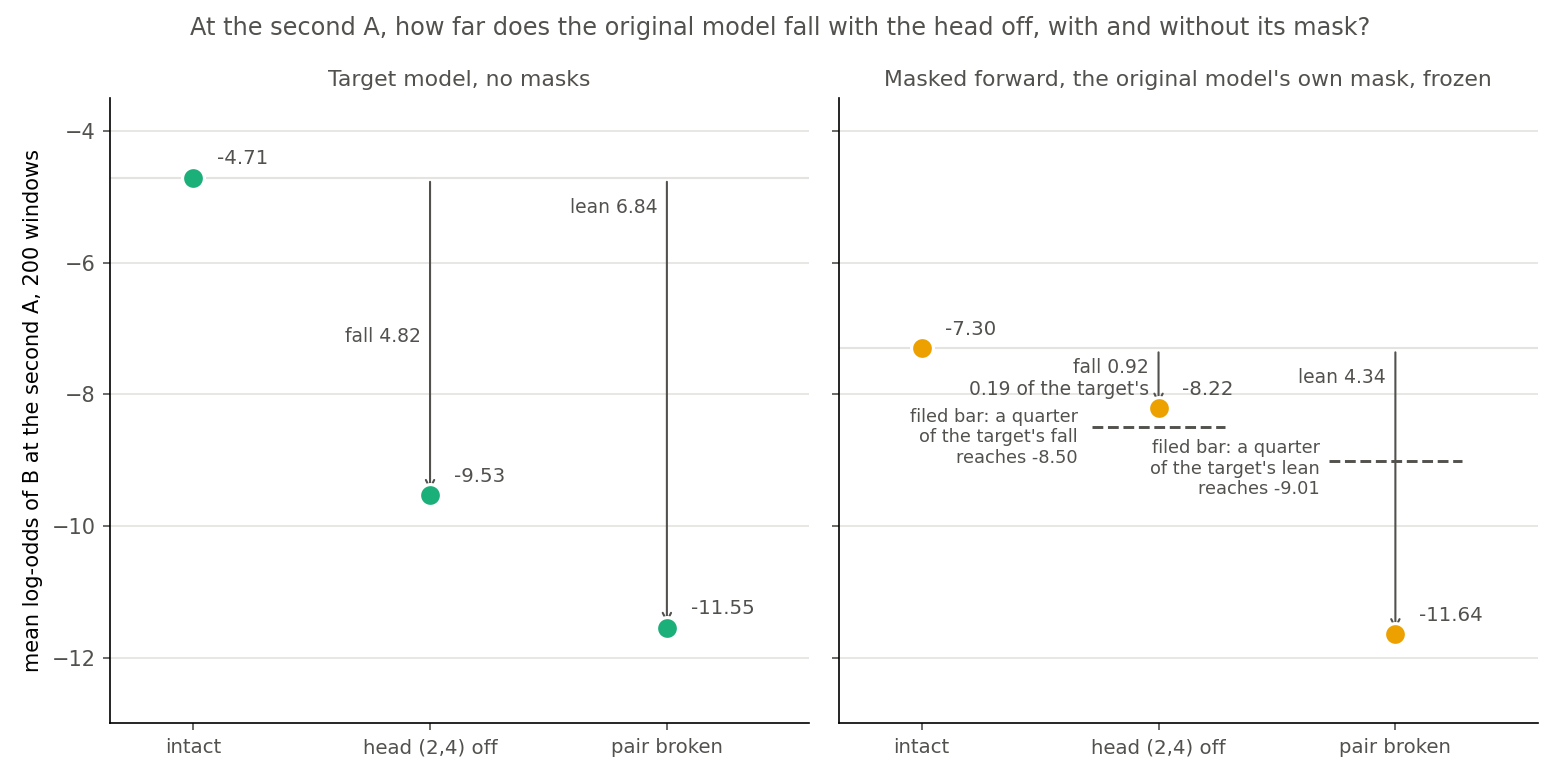

In [14]:
display(Image(filename=str(FIG / "amend4_control.png")))


**Reading it.** The masked fall misses its bar, and the job stopped. The left panel shows the head carrying a large part of the target model's copying. The log-odds of B fall by 4.82 with the head off, which is 0.70 of the lean. The right panel shows the masked forward keeping much of the pair's lean, at 4.34 or 0.64 of the target's. Its fall is 0.92, or 0.19 of the target's, and the head-off point stops short of the dashed bar at a quarter. The lean compares each set of tokens under its own mask, so it holds what the tokens change and what the mask changes. The stage that splits those did not run.

**Side by side, at different positions.** At the marker, Amendment 3 read a masked fall of 0.04 against the target's 1.16. Here it reads 0.92 against 4.82. These are two positions, not a trend.

**Why the masked fall is low: accounts, none chosen.** They are not exclusive, and nothing in this job separates them. One simple reading goes on arithmetic alone. Had the target's copying shrunk evenly by the lean's ratio, the masked fall would be about 3.06, assuming evenness on this scale.

| account | the read that would separate it |
|---|---|
| W₀'s mask passes little of this head's output at the second A; unread here, and shutting was not shown at the marker | how much of the slot's output passes the masked `o_proj` here, weighted over all alive subcomponents |
| the output passes, and other subcomponents carry the lean | the same read, then the head's fall with the slot re-opened, and other heads off |
| the lean sits partly in the frozen mask, which Γ reads from the pair | the split of the lean into tokens and mask; the masks recomputed with the head off here |
| the replacement value behaves differently in the masked forward | own-mask mean and zero ablation here |
| the two forwards are on two precisions, fp32 and bf16 | the masked reads repeated in fp32 |

## What we learned

For `GOALS.md`, nothing moves on new capability against strengthened old, as far as this test goes. The test's question has no reading, and its filed claim and null are both unscored. Any reading from it would also carry the granularity limit: a new circuit built from old subcomponents reads as elicited to VPD. What is new is about W₀ alone. At the position where it copies, its target model depends heavily on this head. Its masked forward responds to the pair far more than to the head's replacement.

## How compelling is the evidence

The verdict comes from a filed rule, and the arithmetic recomputes exactly. This is W₀ alone: one model, one decomposition seed, 200 windows sharing 32 keys. The noise floor is unread, because per-window values were not saved, so the miss of 0.29 log-odds has no standard deviation beside it. The target model's bars hold, so the head and windows behave as filed. The quarter bar has no positive control. Nothing shows the masked fall reading high on a head known to carry behaviour through that forward. The read is blind to which subcomponents pass the head's output and to any effect of the head through Γ, since the mask is frozen.

## Surprises

**Something unexpected happened that I cannot explain.** The plan expected the masked fall to reach a quarter of the target's, and it reached 0.19. The low fall at the marker had already shown this could happen. The cause remains unread. Also, the gap between the two forwards changes with the condition. The masked forward reads 2.59 under the target when intact and 1.31 above it with the head off. With the pair broken the two agree within 0.10.

## What next

The plan's tree sends a failed mask control to the user. It names the weighted slot read, filed then with a reference slot, as the next step to size it. A decision on what runs next is pending, so nothing further is recommended here.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| stage 1, target | W₀ copies here | probability of B at least 0.00315 | 0.00789 | holds |
| stage 1, target | the head carries it | fall at least 1.1628 | 4.817 | holds |
| stage 1, target | W₀ depends on the pair | lean at least 1.5801 | 6.836 | holds |
| stage 1, mask | the masked forward has the lean | at least 0.25 of the target's | 0.635 | holds |
| stage 1, mask | the masked forward has the fall | at least 0.25 of the target's | 0.190 | **missed**, `mask_drops_head` |
| P1, P2, P3 | alignment, closing, gap | as filed | not run | empty |
| verdict | | first that fires | | **`control_failed_mask`** |

**Provenance.** `experiments/induction_cue/results/amend4.json`, job 48945, NVIDIA L40, MATS debug, under a minute, $0. Figure `experiments/induction_cue/plot_amend4.py`. Report: `reports/analyses/2026-11-02_analysis_e62-amend4-control-stop.md`. Independent check: not yet done.

## Departures from the literature

Olsson et al. 2022 zero-ablate a head, on small models, and read induction on repeated random tokens. We mean-ablate, as approved for E62, on word-like windows with an A and B set in. Comparing a parameter decomposition's mask with the head off in the forward only, and between a window and its pair-broken twin, has no source we know of. No threshold is published.

## Not run

The later stages, on all six states and at W₀: whether the 172 subcomponents carry W₀'s own copying, the lean's token part, the re-read of Amendment 3, alignment, every closing share and its reference. The weighted slot read. The masks recomputed with the head off at the second A, own-mask mean and zero ablation, the masked forward in fp32, the slot re-opened by slot share, other heads off here. Per-window values and a standard deviation on the fall. The report's list has the rest, and Amendment 3's list carries over.
